<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Confusion Matrix:
 [[ 62   2]
 [  2 105]]
Accuracy = 97.66%
Precision = 0.981,  Recall = 0.981


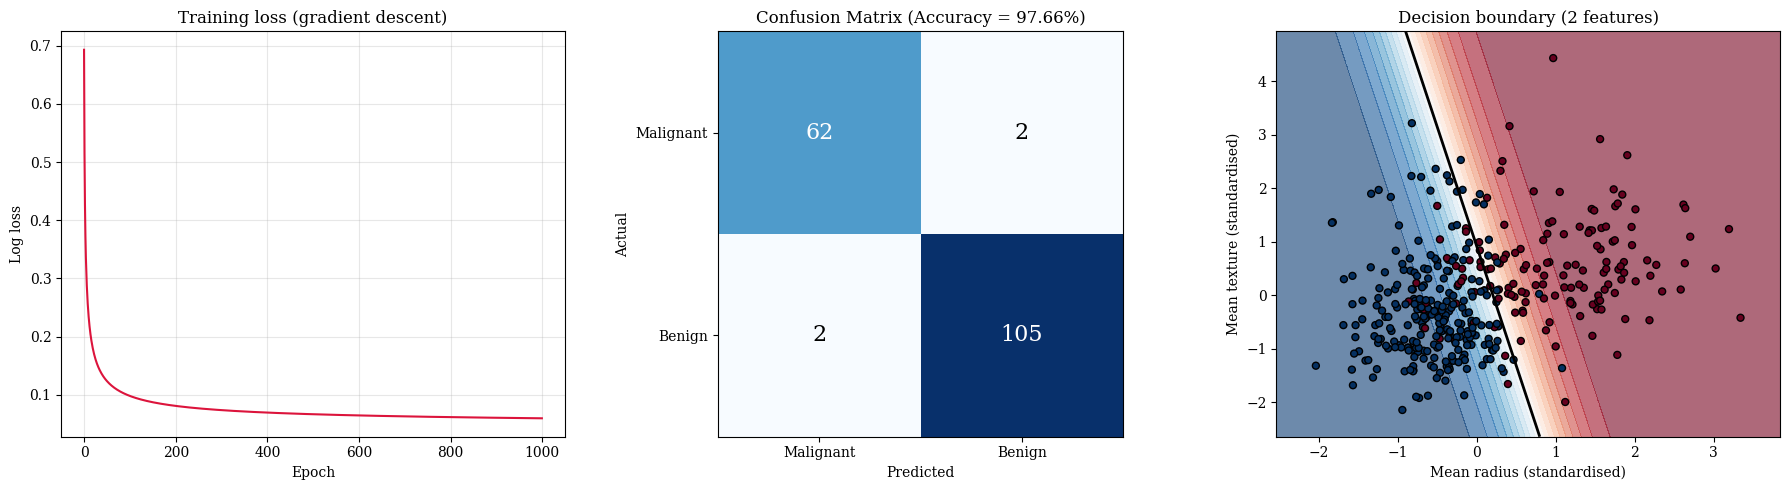

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Standardise features using training statistics
mu, sd = X_train.mean(axis=0), X_train.std(axis=0)

def sigmoid(z): return 1 / (1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.losses = []
        for _ in range(self.epochs):
            p = sigmoid(X @ self.w + self.b)
            self.losses.append(-np.mean(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)))
            self.w -= self.lr * X.T @ (p - y) / len(y)     # gradient descent
            self.b -= self.lr * np.mean(p - y)

    def predict_proba(self, X): return sigmoid(X @ self.w + self.b)
    def predict(self, X): return (self.predict_proba(X) >= 0.5).astype(int)

Xtr, Xte = (X_train - mu) / sd, (X_test - mu) / sd
model = LogisticRegression(lr=0.1, epochs=1000)
model.fit(Xtr, y_train)
y_pred = model.predict(Xte)

cm = np.zeros((2, 2), dtype=int)
for t, p in zip(y_test, y_pred):
    cm[t, p] += 1
accuracy = np.trace(cm) / cm.sum()
print("Confusion Matrix:\n", cm)
print(f"Accuracy = {accuracy*100:.2f}%")
print(f"Precision = {cm[1,1]/(cm[1,1]+cm[0,1]):.3f},  Recall = {cm[1,1]/(cm[1,1]+cm[1,0]):.3f}")

# Separate 2-feature model only to draw a decision boundary
f1, f2 = 0, 1                      # mean radius, mean texture
m2 = LogisticRegression(lr=0.1, epochs=1000)
Z = (X_train[:, [f1, f2]] - mu[[f1, f2]]) / sd[[f1, f2]]
m2.fit(Z, y_train)

# ---- Graphs
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].plot(model.losses, color="crimson")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Log loss"); ax[0].set_title("Training loss (gradient descent)"); ax[0].grid(alpha=.3)

im = ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                   color="white" if cm[i, j] > cm.max()/2 else "black")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Malignant", "Benign"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Malignant", "Benign"])
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
ax[1].set_title(f"Confusion Matrix (Accuracy = {accuracy*100:.2f}%)")

xx, yy = np.meshgrid(np.linspace(Z[:,0].min()-.5, Z[:,0].max()+.5, 200),
                     np.linspace(Z[:,1].min()-.5, Z[:,1].max()+.5, 200))
pp = m2.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax[2].contourf(xx, yy, pp, levels=20, cmap="RdBu", alpha=.6)
ax[2].contour(xx, yy, pp, levels=[0.5], colors="k", linewidths=2)
ax[2].scatter(Z[:,0], Z[:,1], c=y_train, cmap="RdBu", edgecolors="k", s=25)
ax[2].set_xlabel("Mean radius (standardised)"); ax[2].set_ylabel("Mean texture (standardised)")
ax[2].set_title("Decision boundary (2 features)")
plt.tight_layout(); plt.show()